# 전국 아파트 실거래가 예측 프로젝트

**데이터 출처**: 국토교통부 아파트매매 실거래상세자료 (공공데이터포털 Open API)
**목표**: 전국 아파트 실거래가를 예측하는 회귀 모델을 만들고, 어떤 요인이 가격에 영향을 주는지 설명한다.
**범위**: 전국 267개 시군구, 최근 N개월 실거래 데이터

## 진행 순서
1. 사전 준비 (API 키 발급, 패키지 설치)
2. 지역코드(법정동코드) 조회
3. 데이터 수집 (Open API 반복 호출 + 체크포인트 저장)
4. 데이터 통합 및 EDA
5. 피처 엔지니어링
6. 모델링 (Linear → RandomForest → XGBoost 비교)
7. 평가 및 다음 단계

> 이 노트북은 실제 서비스키가 없어도 **DEMO_MODE**로 구조를 확인할 수 있도록 만들어졌습니다.
> 서비스키를 발급받으면 `DEMO_MODE = False` 로 바꾸고 그대로 실행하면 됩니다.


## 1. 사전 준비 — API 인증키 발급 방법

### 1) 공공데이터포털 회원가입
- https://www.data.go.kr 접속 → 우측 상단 **회원가입** (개인 회원으로 충분)

### 2) API 검색 및 활용신청
- 로그인 후 검색창에 **"아파트 매매 실거래가 상세 자료"** 검색
- **정확한 데이터셋명: `국토교통부_아파트 매매 실거래가 상세 자료` (data.go.kr ID: 15126468, 엔드포인트: `RTMSDataSvcAptTradeDev`)**
  - 이름이 비슷한 `국토교통부_아파트 매매 실거래가 자료` (ID: 15126469, "상세"가 빠진 이름, 엔드포인트: `RTMSDataSvcAptTrade`)는 **필드 수가 더 적은 구버전**이므로 헷갈리지 않도록 주의하세요. 이 노트북은 **"상세 자료"(15126468, `...Dev`)** 기준으로 작성되어 있습니다.
  - 분양권전매 실거래가 자료, 아파트 전월세 실거래가 자료는 또 다른 별도 데이터셋입니다 (전세가율 등으로 확장할 때 나중에 추가 신청)
- 상세 페이지에서 **활용신청** 버튼 클릭
- 활용 목적 등 간단한 정보 입력 후 신청 (심의 없이 자동 승인되는 경우가 대부분)

### 3) 승인 대기 및 키 확인
- 보통 **1~2시간 이내** 자동 승인 (일부 API는 최대 1일 소요)
- 승인 후 **마이페이지 → 데이터활용 → 개발계정** 에서 서비스키 확인
- 서비스키는 **Encoding**과 **Decoding** 두 종류가 발급되는데, Python `requests`로 직접 호출할 때는 보통 **Decoding 키**를 사용 (URL 인코딩은 requests가 자동 처리)
- `PublicDataReader` 라이브러리를 쓸 경우도 Decoding 키를 그대로 넣으면 됩니다

### 4) 트래픽 한도 확인
- 개발계정은 보통 **일일 트래픽 한도**가 있습니다 (데이터셋 상세 페이지에 명시, 통상 1,000회 내외이며 운영계정 전환 시 확대 가능)
- 전국 267개 시군구 × 여러 개월을 수집하려면 한도를 초과할 수 있으니, 아래 수집 코드는 **지역/월 단위 체크포인트 저장**으로 설계했습니다 (중단 후 재실행하면 이어서 수집)

### 5) 키 보관 (코드에 직접 쓰지 않기)
터미널/Anaconda Prompt에서 환경변수로 등록해두면 노트북에 키를 하드코딩하지 않아도 됩니다.

```bash
# macOS/Linux (터미널)
export DATA_GO_KR_API_KEY="발급받은_디코딩_키"

# Windows (PowerShell)
setx DATA_GO_KR_API_KEY "발급받은_디코딩_키"
```

등록 후 터미널/Jupyter를 재시작하면 아래 코드에서 `os environ`으로 바로 읽어옵니다.


In [27]:
%pip install numpy pandas PublicDataReader scikit-learn xgboost matplotlib pyarrow --upgrade

  Using cached pandas-3.0.5-cp313-cp313-win_amd64.whl.metadata (19 kB)
  Using cached pyarrow-25.0.1-cp313-cp313-win_amd64.whl.metadata (3.0 kB)
Using cached pyarrow-25.0.1-cp313-cp313-win_amd64.whl (27.9 MB)
  Attempting uninstall: pyarrow
    Found existing installation: pyarrow 21.0.0
    Uninstalling pyarrow-21.0.0:
      Successfully uninstalled pyarrow-21.0.0
  Rolling back uninstall of pyarrow
  Moving to c:\users\uk\anaconda3\lib\site-packages\pyarrow-21.0.0.dist-info\
   from C:\Users\UK\anaconda3\Lib\site-packages\~yarrow-21.0.0.dist-info
  Moving to c:\users\uk\anaconda3\lib\site-packages\pyarrow\__init__.pxd
   from C:\Users\UK\AppData\Local\Temp\pip-uninstall-12c6319u\__init__.pxd
  Moving to c:\users\uk\anaconda3\lib\site-packages\pyarrow\__init__.py
   from C:\Users\UK\AppData\Local\Temp\pip-uninstall-12c6319u\__init__.py
  Moving to c:\users\uk\anaconda3\lib\site-packages\pyarrow\__pycache__\
   from C:\Users\UK\anaconda3\Lib\site-packages\pyarrow\~_pycache__
  Moving t

ERROR: Could not install packages due to an OSError: [WinError 5] 액세스가 거부되었습니다: 'c:\\Users\\UK\\anaconda3\\Lib\\site-packages\\pyarrow\\arrow.dll'
Consider using the `--user` option or check the permissions.



In [28]:
!pip install PublicDataReader pandas numpy scikit-learn xgboost matplotlib tqdm --upgrade


  Using cached pandas-3.0.5-cp313-cp313-win_amd64.whl.metadata (19 kB)


In [66]:
import os
import time
import glob
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from dotenv import load_dotenv   # ← 이 줄 추가

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

# ------------------------------------------------------------------
# 설정
# ------------------------------------------------------------------
DEMO_MODE = False       # 실제 서비스키가 있으면 False 로 변경
load_dotenv()
SERVICE_KEY = os.environ.get("DATA_GO_KR_API_KEY", "")  # 환경변수에서 읽기 (하드코딩 금지)

DATA_DIR = Path("data")
RAW_DIR = DATA_DIR / "raw"          # 지역x월 단위 체크포인트 파일 저장 위치
RAW_DIR.mkdir(parents=True, exist_ok=True)

if not DEMO_MODE and not SERVICE_KEY:
    raise ValueError(
        "DEMO_MODE=False 인데 DATA_GO_KR_API_KEY 환경변수가 비어 있습니다. "
        "서비스키를 환경변수로 설정하거나 DEMO_MODE=True 로 두세요."
    )

print(f"DEMO_MODE = {DEMO_MODE}")

DEMO_MODE = False


## 2. 지역코드(법정동코드) 조회

Open API는 지역을 5자리 **법정동시군구코드(LAWD_CD)** 로 지정합니다.
`PublicDataReader` 가 제공하는 `code_bdong()` 으로 전국 시군구 코드를 한 번에 받아올 수 있습니다 (별도 인증키 불필요).


In [51]:
import PublicDataReader as pdr

def get_nationwide_sigungu_codes() -> pd.DataFrame:
    """전국 시군구 단위 법정동코드 목록을 반환한다 (읍면동 레벨 제외, 폐지되지 않은 코드만)."""
    code_df = pdr.code_bdong()
    sgg = code_df[
        (code_df["읍면동명"] == "") &
        (code_df["시군구명"] != "") &
        (code_df["말소일자"] == "")
    ][["시도명", "시군구명", "시군구코드"]].drop_duplicates().reset_index(drop=True)
    return sgg

sigungu_df = get_nationwide_sigungu_codes()
print(f"전국 시군구 수: {len(sigungu_df)}")
sigungu_df.head(10)


출처: 행정기관(행정동) 및 관할구역(법정동) 변경내역(2024.8.1. 시행)
전국 시군구 수: 267


,시도명,시군구명,시군구코드
0,서울특별시,종로구,11110
1,서울특별시,중구,11140
2,서울특별시,용산구,11170
3,서울특별시,성동구,11200
4,서울특별시,광진구,11215
5,서울특별시,동대문구,11230
6,서울특별시,중랑구,11260
7,서울특별시,성북구,11290
8,서울특별시,강북구,11305
9,서울특별시,도봉구,11320


## 3. 수집 대상(지역/기간) 설정

- 전국 전체를 한 번에 수집하면 호출 수가 많아(시군구 267개 × 개월 수) 시간이 오래 걸리고
  개발계정 일일 트래픽 한도에 걸릴 수 있습니다.
- 그래서 `TEST_SUBSET=True` 이면 서울 5개 구 × 최근 3개월만 우선 수집해 파이프라인을 검증하고,
  문제 없으면 `TEST_SUBSET=False` 로 바꿔 전국 전체를 수집하는 구조로 만들었습니다.


In [52]:
TEST_SUBSET = True   # 처음엔 True로 소규모 검증 후, 전국 수집 시 False로 변경

if TEST_SUBSET:
    target_regions = sigungu_df[sigungu_df["시도명"] == "서울특별시"].head(5)
else:
    target_regions = sigungu_df.copy()

# 수집할 계약월 범위 (YYYYMM), 최근 12개월 예시 -> 필요에 맞게 조정
END_MONTH = pd.Timestamp.today().to_period("M")
START_MONTH = END_MONTH - 11  # 최근 12개월
year_months = [str(p) for p in pd.period_range(START_MONTH, END_MONTH, freq="M")]
year_months = [ym.replace("-", "") for ym in year_months]

print(f"대상 지역 수: {len(target_regions)}, 대상 월 수: {len(year_months)}")
print(f"예상 API 호출 수(지역 x 월): {len(target_regions) * len(year_months)}")


대상 지역 수: 5, 대상 월 수: 12
예상 API 호출 수(지역 x 월): 60


## 4. 데이터 수집 함수

- `fetch_real(...)`: `PublicDataReader.TransactionPrice` 로 실제 API를 호출합니다.
- `fetch_demo(...)`: 서비스키 없이 파이프라인을 검증할 수 있도록 실제 응답과 동일한 컬럼 구조의 **합성 데이터**를 생성합니다.
- 지역x월 조합마다 결과를 `data/raw/{시군구코드}_{연월}.csv` 로 저장해두어, 중간에 중단되어도 이어서 수집할 수 있습니다(체크포인트).


In [53]:
from PublicDataReader import TransactionPrice

if not DEMO_MODE:
    api = TransactionPrice(SERVICE_KEY)

def fetch_real(sigungu_code: str, year_month: str) -> pd.DataFrame:
    return api.get_data(
        property_type="아파트",
        trade_type="매매",
        sigungu_code=sigungu_code,
        year_month=year_month,
    )

def fetch_demo(sigungu_code: str, year_month: str, n: int = 30, seed: int | None = None) -> pd.DataFrame:
    """실제 API 응답과 동일한 주요 컬럼을 갖는 합성 데이터를 생성 (구조 검증용)."""
    rng = np.random.default_rng(seed or (hash((sigungu_code, year_month)) % (2**32)))
    n = rng.integers(5, n)
    base_price = rng.uniform(40000, 150000)  # 만원 단위
    df = pd.DataFrame({
        "시군구코드": sigungu_code,
        "년": int(year_month[:4]),
        "월": int(year_month[4:6]),
        "일": rng.integers(1, 28, n),
        "전용면적": np.round(rng.uniform(39, 135, n), 2),
        "층": rng.integers(1, 25, n),
        "건축년도": rng.integers(1988, 2024, n),
        "거래금액": np.round(base_price + rng.normal(0, 8000, n)).clip(min=5000),
        "아파트": [f"데모아파트{i}" for i in rng.integers(1, 20, n)],
        "법정동": "데모동",
    })
    return df

def collect_transaction_data(regions: pd.DataFrame, months: list[str], sleep_sec: float = 0.2) -> None:
    """지역x월 조합을 순회하며 체크포인트 파일로 저장한다. 이미 저장된 파일은 건너뛴다."""
    total = len(regions) * len(months)
    done = 0
    for _, row in regions.iterrows():
        sgg_code = row["시군구코드"]
        for ym in months:
            out_path = RAW_DIR / f"{sgg_code}_{ym}.csv"
            done += 1
            if out_path.exists():
                continue
            try:
                if DEMO_MODE:
                    df = fetch_demo(sgg_code, ym)
                else:
                    df = fetch_real(sgg_code, ym)
                    time.sleep(sleep_sec)  # 트래픽 한도 보호를 위한 딜레이
                df.to_csv(out_path, index=False, encoding="utf-8-sig")
            except Exception as e:
                print(f"[실패] {row['시도명']} {row['시군구명']} {ym}: {e}")
            if done % 50 == 0 or done == total:
                print(f"진행: {done}/{total}")

collect_transaction_data(target_regions, year_months)


진행: 50/60
진행: 60/60


## 5. 수집 데이터 통합

In [54]:
raw_files = glob.glob(str(RAW_DIR / "*.csv"))
print(f"체크포인트 파일 수: {len(raw_files)}")

df_list = [pd.read_csv(f, encoding="utf-8-sig") for f in raw_files]
raw_df = pd.concat(df_list, ignore_index=True) if df_list else pd.DataFrame()
print(raw_df.shape)
raw_df.head()


체크포인트 파일 수: 60
(6553, 32)


,법정동시군구코드,법정동읍면동코드,법정동지번코드,법정동본번코드,법정동부번코드,도로명,도로명시군구코드,도로명코드,도로명일련번호코드,도로명지상지하코드,...,단지일련번호,해제여부,해제사유발생일,거래유형,중개사소재지,등기일자,아파트동명,매도자,매수자,토지임대부아파트여부
0,11110,17500,1,766,0,숭인동길,11110.0,4100204.0,1.0,0.0,...,11110-2234,NaN,NaN,중개거래,서울 종로구,25.11.28,101,개인,개인,N
1,11110,17400,1,703,0,낙산길,11110.0,4100020.0,2.0,0.0,...,11110-91,NaN,NaN,중개거래,서울 영등포구,25.12.30,206,개인,개인,N
2,11110,11500,1,9,0,사직로8길,11110.0,4100135.0,3.0,0.0,...,11110-2203,NaN,NaN,중개거래,서울 종로구,25.11.28,105,개인,개인,N
3,11110,18000,1,126,0,송월길,11110.0,4100192.0,1.0,NaN,...,11110-2464,NaN,NaN,직거래,NaN,25.11.10,403,개인,개인,N
4,11110,11500,1,9,0,사직로8길,11110.0,4100135.0,3.0,0.0,...,11110-2203,NaN,NaN,중개거래,"경기 성남시 분당구, 서울 종로구",25.12.19,104,개인,개인,N


In [56]:
object_cols = raw_df.select_dtypes(include="object").columns
for col in object_cols:
    raw_df[col] = raw_df[col].astype(str)

raw_df.to_parquet(PROCESSED_DIR / "apt_trade_raw.parquet", index=False)

In [57]:
PROCESSED_DIR = DATA_DIR / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
raw_df.to_parquet(PROCESSED_DIR / "apt_trade_raw.parquet", index=False)


In [62]:
raw_df.head()

,법정동시군구코드,법정동읍면동코드,법정동지번코드,법정동본번코드,법정동부번코드,도로명,도로명시군구코드,도로명코드,도로명일련번호코드,도로명지상지하코드,...,단지일련번호,해제여부,해제사유발생일,거래유형,중개사소재지,등기일자,아파트동명,매도자,매수자,토지임대부아파트여부
0,11110,17500,1,766,0,숭인동길,11110.0,4100204.0,1.0,0.0,...,11110-2234,nan,nan,중개거래,서울 종로구,25.11.28,101,개인,개인,N
1,11110,17400,1,703,0,낙산길,11110.0,4100020.0,2.0,0.0,...,11110-91,nan,nan,중개거래,서울 영등포구,25.12.30,206,개인,개인,N
2,11110,11500,1,9,0,사직로8길,11110.0,4100135.0,3.0,0.0,...,11110-2203,nan,nan,중개거래,서울 종로구,25.11.28,105,개인,개인,N
3,11110,18000,1,126,0,송월길,11110.0,4100192.0,1.0,NaN,...,11110-2464,nan,nan,직거래,nan,25.11.10,403,개인,개인,N
4,11110,11500,1,9,0,사직로8길,11110.0,4100135.0,3.0,0.0,...,11110-2203,nan,nan,중개거래,"경기 성남시 분당구, 서울 종로구",25.12.19,104,개인,개인,N


## 6. 탐색적 데이터 분석 (EDA)

> 실제 API 컬럼명은 데이터셋 버전에 따라 다를 수 있습니다 (예: `거래금액`, `전용면적`, `건축년도`, `층` 등).
> 아래 코드는 컬럼명이 정확히 일치하지 않을 경우를 대비해 존재하는 컬럼만 선택하도록 작성했습니다.


In [63]:
print(raw_df.dtypes)
print("\n결측치 비율:")
print(raw_df.isna().mean().sort_values(ascending=False))


법정동시군구코드        int64
법정동읍면동코드        int64
법정동지번코드         int64
법정동본번코드         int64
법정동부번코드         int64
도로명            object
도로명시군구코드      float64
도로명코드         float64
도로명일련번호코드     float64
도로명지상지하코드     float64
도로명건물본번호코드    float64
도로명건물부번호코드    float64
법정동            object
단지명            object
지번             object
전용면적          float64
계약년도            int64
계약월             int64
계약일             int64
거래금액            int64
층               int64
건축년도            int64
단지일련번호         object
해제여부           object
해제사유발생일        object
거래유형           object
중개사소재지         object
등기일자           object
아파트동명          object
매도자            object
매수자            object
토지임대부아파트여부     object
dtype: object

결측치 비율:
도로명지상지하코드     0.144972
도로명시군구코드      0.005799
도로명건물본번호코드    0.005799
도로명코드         0.005799
도로명건물부번호코드    0.005799
도로명일련번호코드     0.005036
법정동시군구코드      0.000000
법정동읍면동코드      0.000000
법정동부번코드       0.000000
도로명           0.000000
법정동지번코드       0.000000
법정동본번코드       0.0000

In [69]:
raw_df["거래금액"].describe()

count    6.553000e+03
mean     1.589715e+05
std      9.769226e+04
min      5.400000e+03
25%      1.080000e+05
50%      1.505000e+05
75%      1.950000e+05
max      2.500000e+06
Name: 거래금액, dtype: float64

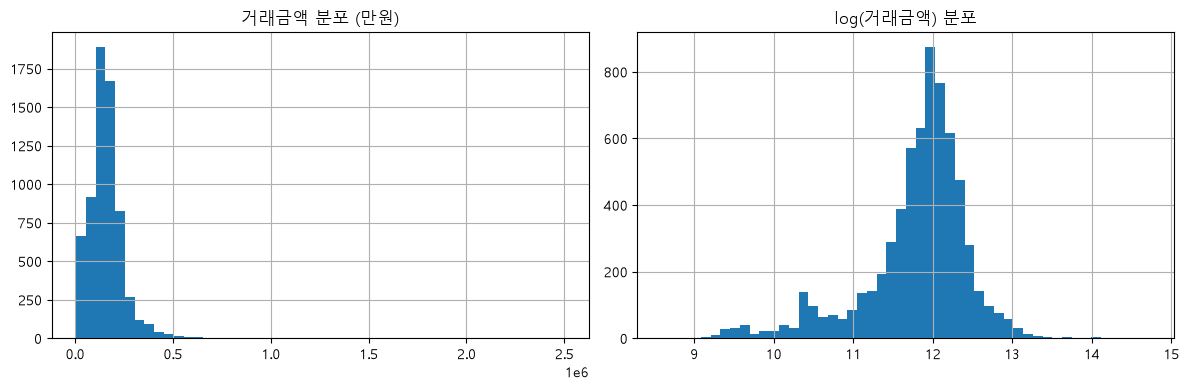

In [ ]:
import matplotlib.pyplot as plt

price_col = "거래금액"
df_eda = raw_df.copy()
df_eda[price_col] = (
    df_eda[price_col].astype(str).str.replace(",", "").str.strip().astype(float)
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df_eda[price_col].hist(bins=50, ax=axes[0])
axes[0].set_title("거래금액 분포 (만원)")

np.log1p(df_eda[price_col]).hist(bins=50, ax=axes[1])
axes[1].set_title("log(거래금액) 분포")
plt.tight_layout()
plt.show()


#17_500_000

## 7. 피처 엔지니어링

- `연식` = 거래년도 - 건축년도
- `거래연월` = 년/월 결합 (시계열 트렌드 피처로 활용 가능)
- `층_구분` = 저층/중층/고층 그룹화
- `시군구코드` → 지역 평균가 기반 타겟 인코딩 (또는 원-핫/라벨 인코딩)
- 타겟 변수는 로그 변환(`log1p(거래금액)`)해 왜도를 줄여 학습 안정성을 높입니다


In [71]:
print(raw_df.columns.tolist())

['법정동시군구코드', '법정동읍면동코드', '법정동지번코드', '법정동본번코드', '법정동부번코드', '도로명', '도로명시군구코드', '도로명코드', '도로명일련번호코드', '도로명지상지하코드', '도로명건물본번호코드', '도로명건물부번호코드', '법정동', '단지명', '지번', '전용면적', '계약년도', '계약월', '계약일', '거래금액', '층', '건축년도', '단지일련번호', '해제여부', '해제사유발생일', '거래유형', '중개사소재지', '등기일자', '아파트동명', '매도자', '매수자', '토지임대부아파트여부']


In [73]:
df_fe = df_eda.copy()

df_fe["연식"] = df_fe["계약년도"] - df_fe["건축년도"]
df_fe["거래연월"] = df_fe["계약년도"] * 100 + df_fe["계약월"]

def floor_group(f):
    if f <= 5:
        return "저층"
    elif f <= 15:
        return "중층"
    return "고층"

df_fe["층_구분"] = df_fe["층"].apply(floor_group)

# 지역별 평균가 기반 타겟 인코딩 (데이터 누수를 막기 위해 실제로는 K-Fold 타겟 인코딩 권장)
region_mean = df_fe.groupby("법정동시군구코드")[price_col].transform("mean")
df_fe["지역평균가"] = region_mean

df_fe["log_price"] = np.log1p(df_fe[price_col])

feature_cols = ["전용면적", "층", "연식", "거래연월", "지역평균가"]
cat_cols = ["층_구분"]
df_model = pd.get_dummies(df_fe[feature_cols + cat_cols + ["log_price"]], columns=cat_cols, drop_first=True)
df_model = df_model.dropna()
df_model.shape

(6553, 8)

In [74]:
print(TEST_SUBSET)

True


## 8. 모델링 — 회귀 모델 비교

- 시계열 특성을 고려해 **최근 기간을 테스트셋으로 분리**하는 것을 권장합니다 (완전 랜덤 분리는 미래 데이터 누수 위험).
- 비교 모델: `LinearRegression` → `RandomForestRegressor` → (설치되어 있다면) `XGBRegressor`


In [75]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

X = df_model.drop(columns=["log_price"])
y = df_model["log_price"]

# 거래연월 기준 시간순 분리 (최근 20%를 테스트로)
order = df_model.index if "거래연월" not in X.columns else X["거래연월"].argsort()
split_idx = int(len(X) * 0.8)
train_idx = order[:split_idx]
test_idx = order[split_idx:]

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

models = {
    "LinearRegression": LinearRegression(),
    "RandomForest": RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
}

try:
    from xgboost import XGBRegressor
    models["XGBoost"] = XGBRegressor(
        n_estimators=300, max_depth=6, learning_rate=0.05, random_state=42, n_jobs=-1
    )
except ImportError:
    print("xgboost 미설치: pip install xgboost 후 재실행하면 비교에 포함됩니다.")

results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    rmse = root_mean_squared_error(y_test, pred)
    mae = mean_absolute_error(y_test, pred)
    r2 = r2_score(y_test, pred)
    results.append({"model": name, "RMSE(log)": rmse, "MAE(log)": mae, "R2": r2})

results_df = pd.DataFrame(results).sort_values("RMSE(log)")
results_df


,model,RMSE(log),MAE(log),R2
1,RandomForest,0.221622,0.143117,0.894190
2,XGBoost,0.231847,0.158131,0.884202
0,LinearRegression,0.476064,0.382635,0.511763


## 9. 평가 — 예측 vs 실제

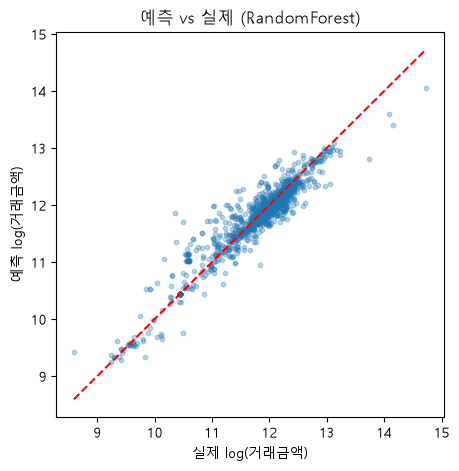

In [77]:
best_name = results_df.iloc[0]["model"]
best_model = models[best_name]
pred_best = best_model.predict(X_test)

plt.figure(figsize=(5, 5))
plt.scatter(y_test, pred_best, alpha=0.3, s=10)
lims = [min(y_test.min(), pred_best.min()), max(y_test.max(), pred_best.max())]
plt.plot(lims, lims, "r--")
plt.xlabel("실제 log(거래금액)")
plt.ylabel("예측 log(거래금액)")
plt.title(f"예측 vs 실제 ({best_name})")
plt.show()


## 10. 분류 — 저평가/고평가 아파트 스크리닝

앞서 만든 회귀 모델(`best_model`)의 예측가를 "적정가"로 보고, 실제 거래금액이 그보다 충분히 낮으면 **저평가**, 충분히 높으면 **고평가**로 라벨링합니다.

- 잔차(%) = (실제가 - 예측가) / 예측가
- 잔차가 `-THRESHOLD` 보다 작으면 → 저평가, `+THRESHOLD` 보다 크면 → 고평가, 그 사이는 → 적정가
- 여기서는 "저평가 여부"를 이진 분류 문제로 단순화해서 다룹니다 (저평가 vs 나머지)

> 주의: 같은 데이터로 학습한 회귀모델의 잔차로 라벨을 만들기 때문에, 회귀모델 자체가 특정 매물군을 체계적으로 못 맞히면 그 편향이 분류 라벨에도 그대로 들어갑니다. 실전에서는 회귀모델을 학습에 안 쓴 홀드아웃 구간의 잔차로 라벨링하는 것이 더 안전합니다.


In [ ]:
results_df

,model,RMSE(log),MAE(log),R2
1,RandomForest,0.221622,0.143117,0.894190
2,XGBoost,0.231847,0.158131,0.884202
0,LinearRegression,0.476064,0.382635,0.511763


In [81]:
print(X.shape)

(6553, 7)


저평가 비율 (test set, out-of-sample 기준): 0.142


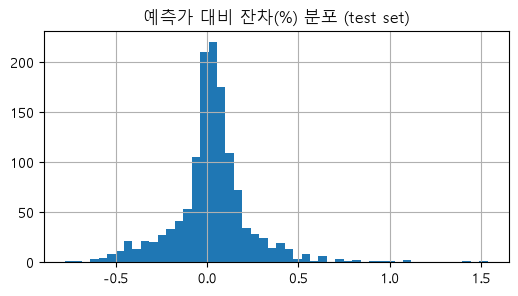

In [82]:
THRESHOLD = 0.15

pred_test_log = best_model.predict(X_test)
residual_pct_test = (np.expm1(y_test) - np.expm1(pred_test_log)) / np.expm1(pred_test_log)

df_clf = X_test.copy()
df_clf["residual_pct"] = residual_pct_test
df_clf["is_underpriced"] = (residual_pct_test < -THRESHOLD).astype(int)

print("저평가 비율 (test set, out-of-sample 기준):", df_clf["is_underpriced"].mean().round(3))
df_clf["residual_pct"].hist(bins=50, figsize=(6, 3))
plt.title("예측가 대비 잔차(%) 분포 (test set)")
plt.show()

In [84]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

X_clf = df_clf.drop(columns=["residual_pct", "is_underpriced"])
y_clf = df_clf["is_underpriced"]

# 회귀와 동일한 시간순 분리 인덱스 재사용
X_clf_train, X_clf_test = X_clf.iloc[train_idx], X_clf.iloc[test_idx]
y_clf_train, y_clf_test = y_clf.iloc[train_idx], y_clf.iloc[test_idx]

clf_models = {
    "LogisticRegression": LogisticRegression(max_iter=1000),
    "RandomForestClassifier": RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
}

try:
    from xgboost import XGBClassifier
    clf_models["XGBClassifier"] = XGBClassifier(
        n_estimators=300, max_depth=6, learning_rate=0.05,
        random_state=42, n_jobs=-1, eval_metric="logloss"
    )
except ImportError:
    print("xgboost 미설치: pip install xgboost 후 재실행하면 비교에 포함됩니다.")

clf_results = []
for name, model in clf_models.items():
    model.fit(X_clf_train, y_clf_train)
    proba = model.predict_proba(X_clf_test)[:, 1]
    pred = model.predict(X_clf_test)
    auc = roc_auc_score(y_clf_test, proba) if y_clf_test.nunique() > 1 else float("nan")
    clf_results.append({
        "model": name,
        "Accuracy": (pred == y_clf_test).mean(),
        "ROC-AUC": auc,
    })
    print(f"\n--- {name} ---")
    print(classification_report(y_clf_test, pred, target_names=["적정/고평가", "저평가"]))

clf_results_df = pd.DataFrame(clf_results).sort_values("ROC-AUC", ascending=False)
clf_results_df


IndexError: positional indexers are out-of-bounds

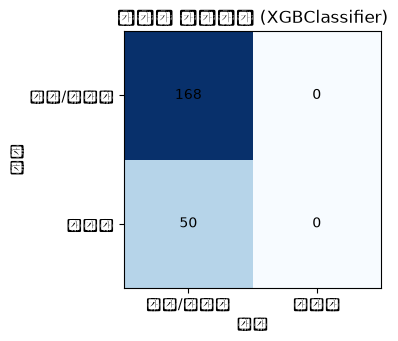

In [ ]:
# 가장 성능 좋은 분류 모델의 컨퓨전 매트릭스
best_clf_name = clf_results_df.iloc[0]["model"]
best_clf = clf_models[best_clf_name]
pred_best_clf = best_clf.predict(X_clf_test)

cm = confusion_matrix(y_clf_test, pred_best_clf)
fig, ax = plt.subplots(figsize=(4, 4))
im = ax.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center")
ax.set_xticks([0, 1]); ax.set_xticklabels(["적정/고평가", "저평가"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["적정/고평가", "저평가"])
ax.set_xlabel("예측"); ax.set_ylabel("실제")
ax.set_title(f"컨퓨전 매트릭스 ({best_clf_name})")
plt.tight_layout()
plt.show()


## 11. 지역 유동성 등급 (거래 활성도 프록시)

실거래 신고 데이터에는 "매물이 안 팔린" 기록이 없어서 "거래성사 여부"를 직접 예측할 수는 없습니다. 대신 **시군구 단위의 거래 활성도(유동성)** 를 프록시로 사용해, 어떤 지역 특성이 거래가 활발한 지역과 관련 있는지 분류 문제로 살펴봅니다.

- 시군구×월 거래건수를 집계 → 분위수 기준으로 `활발` / `보통` / `저조` 3등급으로 라벨링
- 지역 특성(평균 거래금액, 평균 면적, 평균 연식 등)으로 등급을 분류


In [ ]:
region_month_counts = (
    df_fe.groupby(["시군구코드", "거래연월"])
    .size()
    .reset_index(name="거래건수")
)

region_stats = (
    df_fe.groupby("시군구코드")
    .agg(
        평균거래금액=(price_col, "mean"),
        평균전용면적=("전용면적", "mean"),
        평균연식=("연식", "mean"),
        거래건수=(price_col, "count"),
    )
    .reset_index()
)

# 거래건수 기준 3분위 등급 (데이터가 적으면 등급이 균등하지 않을 수 있음)
region_stats["유동성등급"] = pd.qcut(
    region_stats["거래건수"], q=3, labels=["저조", "보통", "활발"], duplicates="drop"
)
region_stats["유동성등급"].value_counts()


유동성등급
저조    2
활발    2
보통    1
Name: count, dtype: int64

In [ ]:
from sklearn.preprocessing import LabelEncoder

liq_feature_cols = ["평균거래금액", "평균전용면적", "평균연식"]
region_model_df = region_stats.dropna(subset=liq_feature_cols + ["유동성등급"])

le = LabelEncoder()
y_liq = le.fit_transform(region_model_df["유동성등급"])
X_liq = region_model_df[liq_feature_cols]

# 지역 수가 적을 수 있으므로(DEMO_MODE 기준) 간단히 RandomForest 하나로 확인
if len(region_model_df) >= 10:
    from sklearn.model_selection import train_test_split
    Xl_train, Xl_test, yl_train, yl_test = train_test_split(
        X_liq, y_liq, test_size=0.3, random_state=42, stratify=y_liq
    )
    liq_clf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
    liq_clf.fit(Xl_train, yl_train)
    pred_liq = liq_clf.predict(Xl_test)
    print(classification_report(yl_test, pred_liq, target_names=le.classes_))
else:
    print(f"지역 수({len(region_model_df)})가 너무 적어 학습/평가 분리가 무의미합니다. "
          f"전국 데이터 수집(TEST_SUBSET=False) 후 재실행하세요.")


지역 수(5)가 너무 적어 학습/평가 분리가 무의미합니다. 전국 데이터 수집(TEST_SUBSET=False) 후 재실행하세요.


## 12. 군집 — 지역별(시군구) 시세 유형 클러스터링

시군구를 "가격 수준 + 변동성 + 규모" 관점의 피처로 표현해 KMeans로 군집화합니다. 실루엣 스코어로 군집 수(k)를 정하고, 각 군집의 특성을 프로파일링합니다.


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

region_price_std = (
    df_fe.groupby("시군구코드")[price_col].std().rename("가격표준편차").reset_index()
)
cluster_df = region_stats.merge(region_price_std, on="시군구코드", how="left")
cluster_df["가격표준편차"] = cluster_df["가격표준편차"].fillna(0)

cluster_feature_cols = ["평균거래금액", "가격표준편차", "평균전용면적", "거래건수"]
cluster_input = cluster_df[cluster_feature_cols].copy()

scaler = StandardScaler()
X_cluster = scaler.fit_transform(cluster_input)

if len(cluster_df) >= 6:
    sil_scores = {}
    for k in range(2, min(7, len(cluster_df))):
        km = KMeans(n_clusters=k, random_state=42, n_init=10)
        labels = km.fit_predict(X_cluster)
        sil_scores[k] = silhouette_score(X_cluster, labels)

    best_k = max(sil_scores, key=sil_scores.get)
    print("k별 실루엣 스코어:", {k: round(v, 3) for k, v in sil_scores.items()})
    print(f"선택된 k = {best_k}")

    final_km = KMeans(n_clusters=best_k, random_state=42, n_init=10)
    cluster_df["cluster"] = final_km.fit_predict(X_cluster)

    display(
        cluster_df.groupby("cluster")[cluster_feature_cols].mean().round(1)
    )
else:
    print(f"시군구 수({len(cluster_df)})가 너무 적어 군집화 의미가 약합니다. "
          f"전국 데이터 수집 후 재실행을 권장합니다.")
    cluster_df["cluster"] = 0


시군구 수(5)가 너무 적어 군집화 의미가 약합니다. 전국 데이터 수집 후 재실행을 권장합니다.


In [ ]:
if "cluster" in cluster_df.columns and cluster_df["cluster"].nunique() > 1:
    fig, ax = plt.subplots(figsize=(6, 5))
    scatter = ax.scatter(
        cluster_df["평균거래금액"], cluster_df["가격표준편차"],
        c=cluster_df["cluster"], cmap="tab10", s=60, alpha=0.8
    )
    ax.set_xlabel("평균 거래금액 (만원)")
    ax.set_ylabel("가격 표준편차 (변동성)")
    ax.set_title("시군구 군집: 가격 수준 vs 변동성")
    legend1 = ax.legend(*scatter.legend_elements(), title="cluster")
    ax.add_artist(legend1)
    plt.tight_layout()
    plt.show()
else:
    print("군집이 1개뿐이라 시각화를 생략합니다 (데이터 확장 후 확인).")


군집이 1개뿐이라 시각화를 생략합니다 (데이터 확장 후 확인).


## 13. 다음 단계 (제안)

1. **실제 API 키 발급 후 `DEMO_MODE=False`, `TEST_SUBSET=False`** 로 전환해 전국 데이터를 실제로 수집
2. **지하철역 거리 / 학군 점수** 등 외부 피처 결합 (서울시 열린데이터광장, 국가공간정보포털 등)
3. **SHAP**으로 피처 중요도 및 방향성 해석 (`pip install shap`)
4. **지도 시각화**: Folium/Kepler.gl로 지역별 가격 히트맵 제작
5. **저평가/고평가 스크리닝 도구**: 모델 예측가 대비 실제 호가/실거래가 괴리율 계산해 순위화
6. 데이터 규모가 커지면 `LightGBM`/`CatBoost`, 그리고 딥러닝(MLP, TabNet 등) 비교 실험 추가
7. **저평가 분류(10절)**: 회귀모델 학습에 안 쓴 홀드아웃 잔차로 라벨을 다시 만들어 데이터 누수 없이 재검증
8. **유동성 등급(11절)**: 전국 데이터로 확장해 지역 수를 늘린 뒤 등급별 특성 차이를 SHAP으로 해석
9. **군집(12절)**: 군집 결과를 Folium 지도에 색상으로 입혀 "군집별 지역 분포" 시각화

---
*이 노트북은 DEMO_MODE 합성 데이터로 구조를 검증했습니다. 실제 서비스키 발급 후 동일한 코드로 바로 전국 데이터 수집이 가능합니다.*
